# Öneri Algoritmaları Projesi (Recommendation Systems Project)
## 02. Zamansal Veri Hazırlama ve Ayrım Stratejisi Tasarımı (Temporal Data Preparation & Split Strategy Design)

**Veri Seti:** GroupLens MovieLens 32M Benchmark Dataset  
**Proje Kök Dizini:** `C:\OneriAlgoritmalariProjesi`  
**Orijinal Veri Seti Konumu:** `C:\ml-32m` (Salt Okunur / Read-Only)  
**Kullanılan Çekirdek (Kernel):** `Recommendation Systems - Project` (`recommendation-systems-project`)

---

### Görevin Amacı ve Metodolojik Kapsamı
Bu çalışma defteri, MovieLens 32M veri seti üzerinde geliştirilecek tüm öneri modelleri için **tekrarlanabilir (reproducible), gerçekçi ve zamansal bilgi sızıntısından (temporal data leakage) kesin olarak arındırılmış** bir veri hazırlama ve eğitim/test ayrımı altyapısı tasarlamak ve doğrulamak amacıyla oluşturulmuştur.

> [!IMPORTANT]
> **Bu görev bir model eğitimi görevi değildir.** Bu aşamada hiçbir öneri modeli eğitilmeyecek, hiperparametre optimizasyonu yapılmayacak, Precision@10/Recall@10/NDCG@10 metrikleri hesaplanmayacak ve orijinal veri setine kalıcı bir filtre uygulanmayacaktır. Amaç, ilerideki tüm modellerin üzerinde adil biçimde yarışacağı sağlam bir değerlendirme altyapısı kurmaktır.

### Temel Veri Bütünlüğü Prensipleri:
1. **Orijinal Verinin Korunması:** `C:\ml-32m` konumundaki CSV dosyaları salt okunur kabul edilir; hiçbir dosya üzerine yazılmaz, taşınmaz veya çoğaltılmaz.
2. **Zamansal Sızıntının Önlenmesi (Leakage Prevention):** Rastgele etkileşim düzeyinde bölme (random split) kesinlikle kullanılmaz; etkileşimler zaman damgasına göre kronolojik sıralanır.
3. **Determinizm ve Güvenceler (Assertions):** Tüm işlemler sabit tohum ($42$) ve çoklu anahtar sıralaması ile deterministiktir. Sızıntısızlık (`max(train_ts) < min(test_ts)`) açık kod güvenceleriyle (assertions) teyit edilir.
4. **Bellek Korunumu:** Yoğun matris (dense matrix) tahsisinden kaçınılır; bellek optimizasyonlu tipler kullanılır.

## Bölüm 1 — Giriş ve Çalışma Ortamı (Introduction & Environment)

Bu bölümde çalışma ortamı başlatılmakta, `config.yaml` üzerinden veri yolları yüklenmekte ve tekrarlanabilirliği sağlamak amacıyla sabit rastgelelik tohumu atanmaktadır.

In [1]:
import os
import sys
import platform
import time
import yaml
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Tekrarlanabilirlik için sabit tohum
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Grafik görselleştirme ve stil ayarları
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300

# Proje dizin hiyerarşisi ve config.yaml yükleme
current_dir = os.getcwd()
if os.path.basename(current_dir) == 'notebooks':
    project_root = os.path.abspath(os.path.join(current_dir, '..'))
else:
    project_root = os.path.abspath(current_dir)

config_path = os.path.join(project_root, 'config.yaml')
with open(config_path, 'r', encoding='utf-8') as f:
    config = yaml.safe_load(f)

dataset_dir = config['dataset']['directory']
results_dir = os.path.join(project_root, 'results')
figures_dir = os.path.join(results_dir, 'figures')
os.makedirs(figures_dir, exist_ok=True)

print("=== Çalışma Ortamı Bilgileri ===")
print(f"Platform: {platform.platform()} | Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | Matplotlib: {matplotlib.__version__}")
print(f"Proje Kök Dizini  : {project_root}")
print(f"Veri Seti Dizini : {dataset_dir}")
print(f"Sonuçlar Dizini  : {results_dir}")
print(f"Sabit Tohum      : {RANDOM_SEED}")
assert os.path.isdir(dataset_dir), f"Veri seti dizini bulunamadı: {dataset_dir}"


=== Çalışma Ortamı Bilgileri ===
Platform: Windows-11-10.0.26200-SP0 | Python: 3.14.7
NumPy: 2.5.4 | Pandas: 3.1.0 | Matplotlib: 3.11.2
Proje Kök Dizini  : C:\OneriAlgoritmalariProjesi
Veri Seti Dizini : C:/ml-32m
Sonuçlar Dizini  : C:\OneriAlgoritmalariProjesi\results
Sabit Tohum      : 42


## Bölüm 2 — Veri Yükleme ve Bellek Optimizasyonu (Data Loading)

Bu aşamada yalnızca bu görev için gerekli olan `ratings.csv` ve `movies.csv` dosyaları okunacaktır. Bellek taşmasını engellemek için `ratings.csv` sütunları optimize veri tipleriyle (`userId`: int32, `movieId`: int32, `rating`: float32, `timestamp`: int64) belleğe alınacaktır.

In [2]:
# Veri setlerinin optimize veri tipleriyle okunması
t0 = time.time()

ratings_path = os.path.join(dataset_dir, config['dataset']['ratings'])
movies_path = os.path.join(dataset_dir, config['dataset']['movies'])

dtypes_ratings = {
    'userId': 'int32',
    'movieId': 'int32',
    'rating': 'float32',
    'timestamp': 'int64'
}

ratings_df = pd.read_csv(ratings_path, dtype=dtypes_ratings)
movies_df = pd.read_csv(movies_path)

t_load = time.time() - t0
mem_mb = ratings_df.memory_usage(deep=True).sum() / (1024**2)

print(f"Veri seti {t_load:.2f} saniyede yüklendi.")
print(f"ratings_df Satır Sayısı: {len(ratings_df):,} | RAM Kullanımı: {mem_mb:.2f} MB")
print(f"movies_df Satır Sayısı : {len(movies_df):,}")

# İlk 5 örnek kayıt
display(ratings_df.head())


Veri seti 0.93 saniyede yüklendi.
ratings_df Satır Sayısı: 32,000,204 | RAM Kullanımı: 610.36 MB
movies_df Satır Sayısı : 87,585


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


## Bölüm 3 — Kronolojik Sıralama ve Determinizm (Chronological Ordering & Determinism)

`ratings.csv` dosyası orijinal halinde zaman damgasına göre mutlak sırada değildir; `userId` ve `movieId` bazlı sıralanmıştır. Zamansal bir ayrım yapabilmek için tüm etkileşimler zaman damgasına göre kronolojik olarak sıralanmalıdır.

### Eşit Zaman Damgalarının (Ties) Yönetimi:
Aynı saniyede gerçekleşen birden fazla etkileşimin bulunması durumunda sıralamanın kararsız (nondeterministic) olmasını engellemek amacıyla **üçlü bileşik anahtar** ile sıralama yapılacaktır:
$$\text{Sıralama Anahtarları} = [\text{'timestamp'}, \text{'userId'}, \text{'movieId'}]$$
Bu sayede sıralama tamamen kararlı ve tekrarlanabilir hale getirilmektedir.

In [3]:
# Kronolojik sıralama işlemi (timestamp, userId, movieId)
t0 = time.time()
ratings_df = ratings_df.sort_values(by=['timestamp', 'userId', 'movieId']).reset_index(drop=True)
t_sort = time.time() - t0

min_ts = ratings_df['timestamp'].min()
max_ts = ratings_df['timestamp'].max()
min_date = pd.to_datetime(min_ts, unit='s', utc=True)
max_date = pd.to_datetime(max_ts, unit='s', utc=True)

print(f"Kronolojik sıralama {t_sort:.2f} saniyede tamamlandı.")
print(f"En Erken Etkileşim Zamanı : {min_date} (Timestamp: {min_ts:,})")
print(f"En Geç Etkileşim Zamanı   : {max_date} (Timestamp: {max_ts:,})")
print(f"Toplam Zaman Aralığı       : {(max_date - min_date).days:,} Gün")

# Sıralanmış ilk ve son 3 satır
print("\n--- İlk 3 Etkileşim (En Eski) ---")
display(ratings_df.head(3))

print("\n--- Son 3 Etkileşim (En Yeni) ---")
display(ratings_df.tail(3))


Kronolojik sıralama 6.04 saniyede tamamlandı.
En Erken Etkileşim Zamanı : 1995-01-09 11:46:44+00:00 (Timestamp: 789,652,004)
En Geç Etkileşim Zamanı   : 2023-10-13 02:29:07+00:00 (Timestamp: 1,697,164,147)
Toplam Zaman Aralığı       : 10,503 Gün

--- İlk 3 Etkileşim (En Eski) ---


,userId,movieId,rating,timestamp
0,25062,1176,4.0,789652004
1,30917,21,3.0,789652009
2,30917,47,5.0,789652009



--- Son 3 Etkileşim (En Yeni) ---


,userId,movieId,rating,timestamp
32000201,54315,194947,2.5,1697164060
32000202,54315,104457,2.5,1697164098
32000203,54315,116989,2.5,1697164147


## Bölüm 4 — Zamansal Ayrım Alternatifleri (Temporal Split Alternatives)

Tavsiye sistemleri literatüründe rastgele etkileşim düzeyinde ayrım (random interaction split), gelecekteki etkileşimlerin geçmişi tahmin etmek için kullanılmasına yol açar. Bu durum **zamansal sızıntıya (temporal data leakage)** neden olarak çevrimdışı doğruluk metriklerinin gerçekçi olmayan biçimde yapay yüksek çıkmasına sebebiyet verir.

Gerçek dünya senaryosunda bir öneri motoru yalnızca geçmiş etkileşimleri bilmekte ve gelecekteki etkileşimleri tahmin etmeye çalışmaktadır. Bu nedenle **kronolojik kesme stratejisi (global chronological cutoff)** uygulanmalıdır.

### Karşılaştırılan Zamansal Ayrım Alternatifleri:
1. **Alternatif 1 — Takvimsel Kesme 1 (Calendar Cutoff: 2020-01-01 00:00:00 UTC):**
   - $T_{\text{split}} = 1,577,836,800$.
   - **Gerekçe:** Sistemin ilk 25 yıllık (1995–2019) zengin geçmişini eğitim kümesine tahsis eder. Sonraki ~3.75 yıllık dönemi (2020–2023) test kümesi olarak belirler. Toplam etkileşimlerin yaklaşık %85.5'ini eğitimde, %14.5'ini testte tutar.
2. **Alternatif 2 — Takvimsel Kesme 2 (Calendar Cutoff: 2021-01-01 00:00:00 UTC):**
   - $T_{\text{split}} = 1,609,459,200$.
   - **Gerekçe:** Makine öğreniminde yaygın kabul gören yaklaşık %90 eğitim / %10 test oranını sağlar (Gerçekleşen: %90.8 eğitim / %9.2 test). Son ~2.75 yılı (2021–2023) test dönemi olarak ayırır.
3. **Alternatif 3 — Kümülatif Etkileşim Yüzdeliği Kesmesi (Interaction Quantile Cutoff: %80 / %20):**
   - $T_{\text{split}} = 1,538,551,302$ (2018-10-03 07:21:42 UTC).
   - **Gerekçe:** Kronolojik sıralanmış etkileşim hacminin tam olarak %80'ini eğitim kümesine, geriye kalan %20'sini test kümesine tahsis eden kanonik bir Pareto hacim ayrımıdır.

In [4]:
# 3 Alternatifin Sayısal Hesaplanması ve Karşılaştırma Tablosunun Oluşturulması
total_users = ratings_df['userId'].nunique()
total_movies = ratings_df['movieId'].nunique()
total_ratings = len(ratings_df)

cutoffs = {
    'Alternatif 1: 2020-01-01 UTC (~85.5 / 14.5)': int(pd.Timestamp('2020-01-01 00:00:00', tz='UTC').timestamp()),
    'Alternatif 2: 2021-01-01 UTC (~90.8 / 9.2)': int(pd.Timestamp('2021-01-01 00:00:00', tz='UTC').timestamp()),
    'Alternatif 3: %80 Kümülatif (2018-10-03 UTC)': int(ratings_df['timestamp'].quantile(0.80))
}

comparison_records = []

for name, cutoff in cutoffs.items():
    train_df = ratings_df[ratings_df['timestamp'] < cutoff]
    test_df = ratings_df[ratings_df['timestamp'] >= cutoff]
    
    n_train = len(train_df)
    n_test = len(test_df)
    
    train_users = set(train_df['userId'].unique())
    test_users = set(test_df['userId'].unique())
    
    train_movies = set(train_df['movieId'].unique())
    test_movies = set(test_df['movieId'].unique())
    
    # Değerlendirilebilir kullanıcılar (Hem eğitimde hem testte bulunanlar)
    eval_users = train_users.intersection(test_users)
    n_eval_users = len(eval_users)
    pct_eval_users = (n_eval_users / total_users) * 100.0
    
    # Test etkileşimlerinin ayrımı
    eval_test_mask = test_df['userId'].isin(eval_users)
    eval_test_interactions = int(eval_test_mask.sum())
    excluded_test_interactions = n_test - eval_test_interactions
    
    # Zaman damgası sınır kontrolü
    max_train_ts = int(train_df['timestamp'].max())
    min_test_ts = int(test_df['timestamp'].min())
    leakage_safe = (max_train_ts < min_test_ts)
    
    comparison_records.append({
        'Alternatif': name,
        'Kesme Zaman Damgası': cutoff,
        'Kesme Tarihi (UTC)': str(pd.to_datetime(cutoff, unit='s', utc=True)),
        'Eğitim Etkileşim Sayısı': n_train,
        'Eğitim Oranı (%)': (n_train / total_ratings) * 100.0,
        'Test Etkileşim Sayısı': n_test,
        'Test Oranı (%)': (n_test / total_ratings) * 100.0,
        'Eğitim Tekil Kullanıcı': len(train_users),
        'Test Tekil Kullanıcı': len(test_users),
        'Eğitim Tekil Film': len(train_movies),
        'Test Tekil Film': len(test_movies),
        'Değerlendirilebilir Kullanıcı': n_eval_users,
        'Değerlendirilebilir Kullanıcı Oranı (%)': pct_eval_users,
        'Değerlendirilebilir Test Etkileşimi': eval_test_interactions,
        'Kapsam Dışı Test Etkileşimi': excluded_test_interactions,
        'Sızıntısızlık (max_tr < min_te)': leakage_safe
    })

comparison_df = pd.DataFrame(comparison_records)

# CSV olarak kaydetme
csv_out_path = os.path.join(results_dir, 'temporal_split_comparison.csv')
comparison_df.to_csv(csv_out_path, index=False, encoding='utf-8')
print(f"Karşılaştırma tablosu kaydedildi: {csv_out_path}\n")

# Formatlı görüntüleme
display_df = comparison_df.copy()
display_df['Eğitim Etkileşim Sayısı'] = display_df['Eğitim Etkileşim Sayısı'].apply(lambda x: f"{x:,}")
display_df['Test Etkileşim Sayısı'] = display_df['Test Etkileşim Sayısı'].apply(lambda x: f"{x:,}")
display_df['Eğitim Oranı (%)'] = display_df['Eğitim Oranı (%)'].apply(lambda x: f"%{x:.2f}")
display_df['Test Oranı (%)'] = display_df['Test Oranı (%)'].apply(lambda x: f"%{x:.2f}")
display_df['Eğitim Tekil Kullanıcı'] = display_df['Eğitim Tekil Kullanıcı'].apply(lambda x: f"{x:,}")
display_df['Test Tekil Kullanıcı'] = display_df['Test Tekil Kullanıcı'].apply(lambda x: f"{x:,}")
display_df['Eğitim Tekil Film'] = display_df['Eğitim Tekil Film'].apply(lambda x: f"{x:,}")
display_df['Test Tekil Film'] = display_df['Test Tekil Film'].apply(lambda x: f"{x:,}")
display_df['Değerlendirilebilir Kullanıcı'] = display_df['Değerlendirilebilir Kullanıcı'].apply(lambda x: f"{x:,}")
display_df['Değerlendirilebilir Kullanıcı Oranı (%)'] = display_df['Değerlendirilebilir Kullanıcı Oranı (%)'].apply(lambda x: f"%{x:.2f}")
display_df['Değerlendirilebilir Test Etkileşimi'] = display_df['Değerlendirilebilir Test Etkileşimi'].apply(lambda x: f"{x:,}")
display_df['Kapsam Dışı Test Etkileşimi'] = display_df['Kapsam Dışı Test Etkileşimi'].apply(lambda x: f"{x:,}")

display(display_df.T)


Karşılaştırma tablosu kaydedildi: C:\OneriAlgoritmalariProjesi\results\temporal_split_comparison.csv



,0,1,2
Alternatif,Alternatif 1: 2020-01-01 UTC (~85.5 / 14.5),Alternatif 2: 2021-01-01 UTC (~90.8 / 9.2),Alternatif 3: %80 Kümülatif (2018-10-03 UTC)
Kesme Zaman Damgası,1577836800,1609459200,1538551302
Kesme Tarihi (UTC),2020-01-01 00:00:00+00:00,2021-01-01 00:00:00+00:00,2018-10-03 07:21:42+00:00
Eğitim Etkileşim Sayısı,"27,364,974","29,053,133","25,600,163"
Eğitim Oranı (%),%85.51,%90.79,%80.00
Test Etkileşim Sayısı,"4,635,230","2,947,071","6,400,041"
Test Oranı (%),%14.49,%9.21,%20.00
Eğitim Tekil Kullanıcı,"179,419","187,950","170,491"
Test Tekil Kullanıcı,"29,346","20,970","38,272"
Eğitim Tekil Film,"59,952","66,750","50,977"


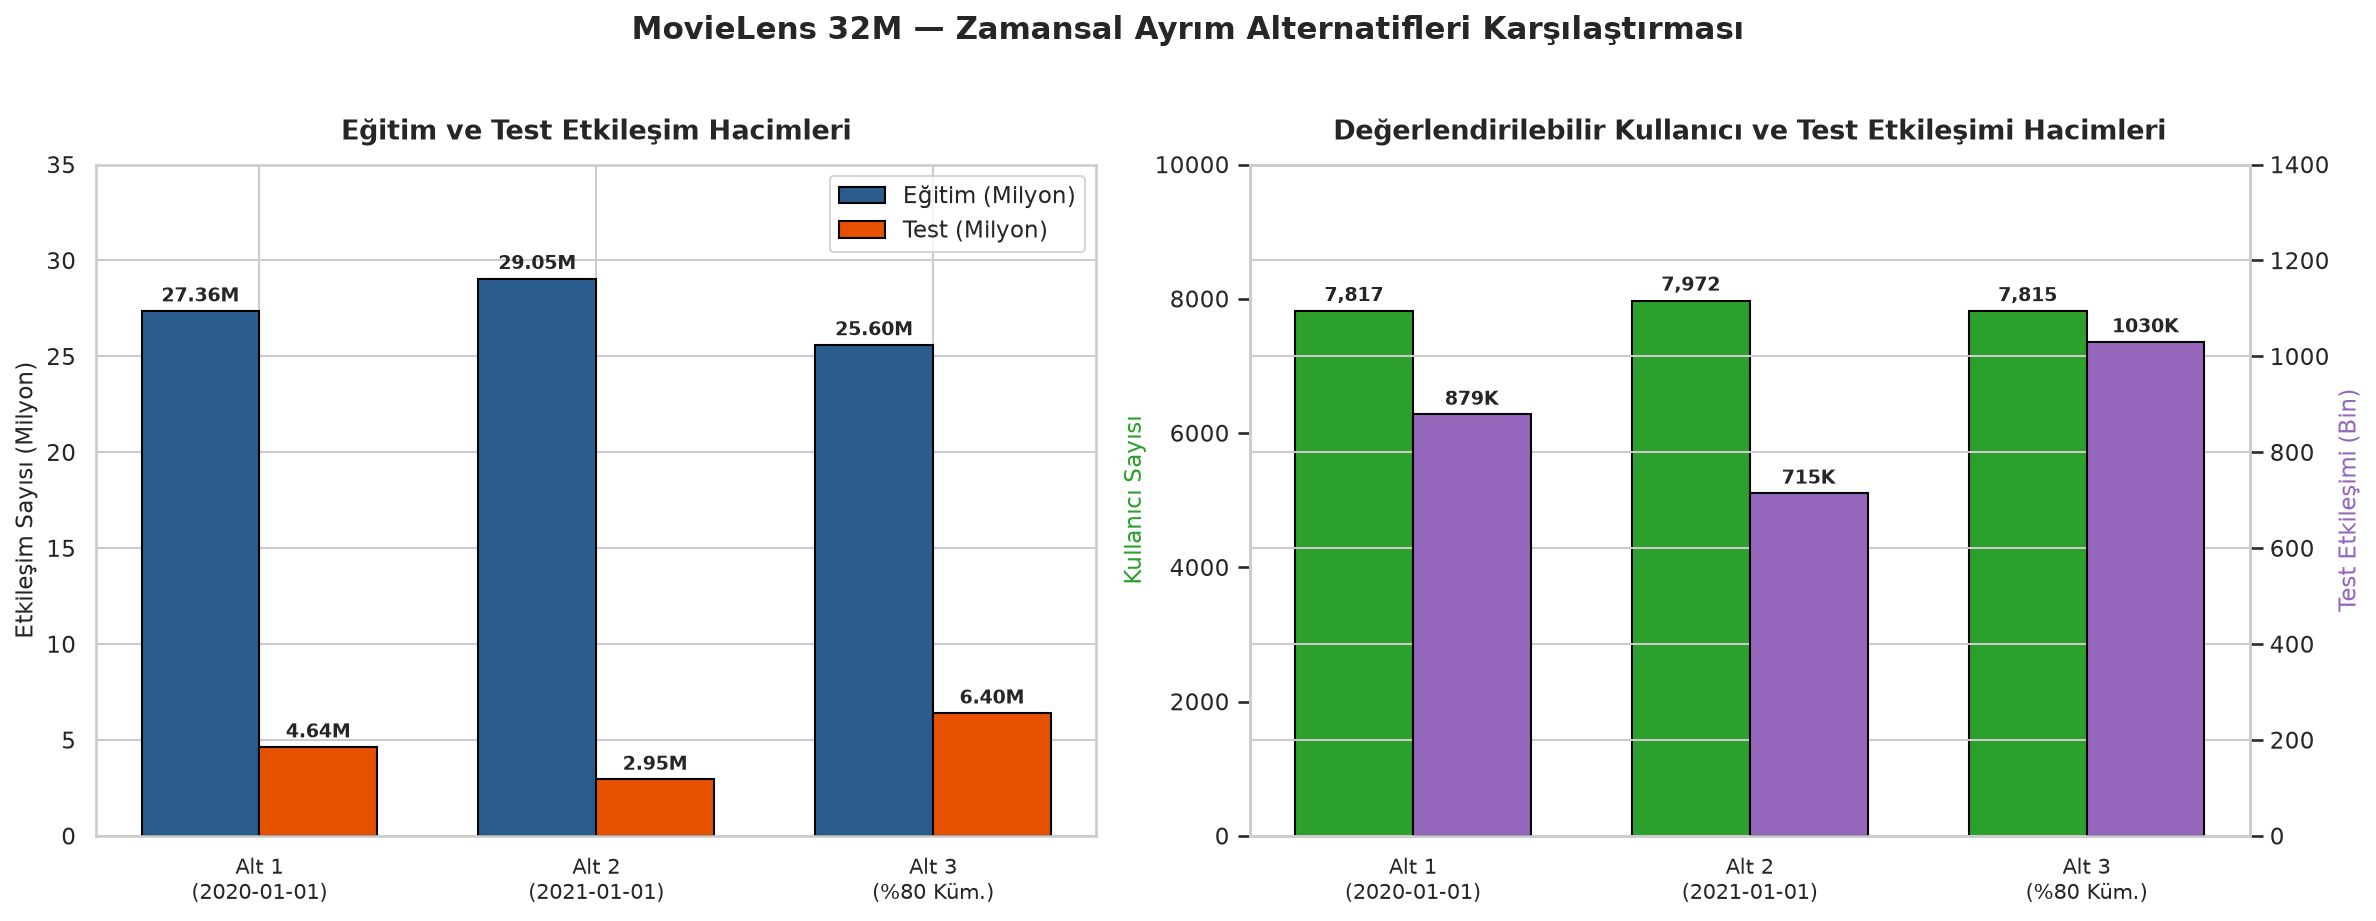

Görselleştirme kaydedildi: C:\OneriAlgoritmalariProjesi\results\figures\temporal_split_comparison.png


In [5]:
# Zamansal Ayrım Alternatiflerinin Görsel Karşılaştırması
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

alt_labels = ['Alt 1\n(2020-01-01)', 'Alt 2\n(2021-01-01)', 'Alt 3\n(%80 Küm.)']
train_counts = [r['Eğitim Etkileşim Sayısı'] / 1e6 for r in comparison_records]
test_counts = [r['Test Etkileşim Sayısı'] / 1e6 for r in comparison_records]

# Panel 1: Etkileşim Hacmi Dağılımı
x = np.arange(len(alt_labels))
width = 0.35
b1 = ax1.bar(x - width/2, train_counts, width, label='Eğitim (Milyon)', color='#2b5c8f', edgecolor='black')
b2 = ax1.bar(x + width/2, test_counts, width, label='Test (Milyon)', color='#e65100', edgecolor='black')

ax1.set_title('Eğitim ve Test Etkileşim Hacimleri', fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel('Etkileşim Sayısı (Milyon)', fontsize=11)
ax1.set_xticks(x)
ax1.set_xticklabels(alt_labels, fontsize=10)
ax1.legend(frameon=True)
ax1.set_ylim(0, 35)

for bar in b1:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f"{bar.get_height():.2f}M", ha='center', fontsize=9, fontweight='bold')
for bar in b2:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f"{bar.get_height():.2f}M", ha='center', fontsize=9, fontweight='bold')

# Panel 2: Değerlendirilebilir Kullanıcı ve Etkileşimler
eval_user_counts = [r['Değerlendirilebilir Kullanıcı'] for r in comparison_records]
eval_int_counts = [r['Değerlendirilebilir Test Etkileşimi'] / 1e3 for r in comparison_records]

ax2_twin = ax2.twinx()
b3 = ax2.bar(x - width/2, eval_user_counts, width, label='Değerlendirilebilir Kullanıcı', color='#2ca02c', edgecolor='black')
b4 = ax2_twin.bar(x + width/2, eval_int_counts, width, label='Değerlendirilebilir Test Etkileşimi (Bin)', color='#9467bd', edgecolor='black')

ax2.set_title('Değerlendirilebilir Kullanıcı ve Test Etkileşimi Hacimleri', fontsize=13, fontweight='bold', pad=12)
ax2.set_ylabel('Kullanıcı Sayısı', fontsize=11, color='#2ca02c')
ax2_twin.set_ylabel('Test Etkileşimi (Bin)', fontsize=11, color='#9467bd')
ax2.set_xticks(x)
ax2.set_xticklabels(alt_labels, fontsize=10)
ax2.set_ylim(0, 10000)
ax2_twin.set_ylim(0, 1400)
ax2.grid(False)

for bar in b3:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 150, f"{int(bar.get_height()):,}", ha='center', fontsize=9, fontweight='bold')
for bar in b4:
    ax2_twin.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20, f"{bar.get_height():.0f}K", ha='center', fontsize=9, fontweight='bold')

plt.suptitle('MovieLens 32M — Zamansal Ayrım Alternatifleri Karşılaştırması', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
fig_split_path = os.path.join(figures_dir, 'temporal_split_comparison.png')
plt.savefig(fig_split_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Görselleştirme kaydedildi: {fig_split_path}")


## Bölüm 6 — Değerlendirilebilir Kullanıcı Analizi (Evaluable User Analysis)

Global zamansal ayrımın ortaya koyduğu en kritik yapısal olgu **kullanıcı ömür döngüsü (user lifecycle)** dinamikleridir.

### Değerlendirilebilir Kullanıcı (Evaluable User) Tanımı:
Kişiselleştirilmiş bir tavsiye modelinin test edilebilmesi için kullanıcının:
1. **Eğitim döneminde en az 1 etkileşiminin bulunması ($|R_{\text{train}}(u)| \ge 1$):** Modelin kullanıcının geçmiş zevklerini öğrenebilmesi (user profile / latent vector) için şarttır.
2. **Test döneminde en az 1 etkileşiminin bulunması ($|R_{\text{test}}(u)| \ge 1$):** Modelin ürettiği önerilerin test gerçekliğiyle (ground-truth) karşılaştırılabilmesi için şarttır.

Bu iki koşulu aynı anda sağlayan kullanıcı kümesine **Değerlendirilebilir Kullanıcılar (Evaluable Users)** denir:
$$U_{\text{eval}} = U_{\text{train}} \cap U_{\text{test}}$$

### Kapsam Dışı Kalan Kullanıcılar ve Veri Silmeme İlkesi:
- **Yalnızca Eğitimde Olan Kullanıcılar (Train-Only Users):** Sisteme 1995–2019 arasında girmiş, filmlerini oylamış ve test periyodunda sisteme girmemiş kullanıcılardır (~171K kullanıcı). Modelin öğreniminde genel desenleri zenginleştirirler.
- **Yalnızca Testte Olan Kullanıcılar (Test-Only / Cold-Start Users):** Sisteme ilk kez test periyodunda katılmış yeni kullanıcılardır (~21.5K kullanıcı). Bu kullanıcıların eğitim geçmişi olmadığı için standart işbirlikçi filtreleme algoritmaları bunlara kişiselleştirilmiş tahmin üretemez.
- **Sessizce Silmeme İlkesi (No Silent Removal):** Bu test etkileşimleri veri setinden gizlice silinmez. Kişiselleştirilmiş modeller $U_{\text{eval}}$ üzerinde değerlendirilirken; soğuk başlangıç kullanıcıları raporlamada ayrı bir kategori olarak şeffaf biçimde sunulur.

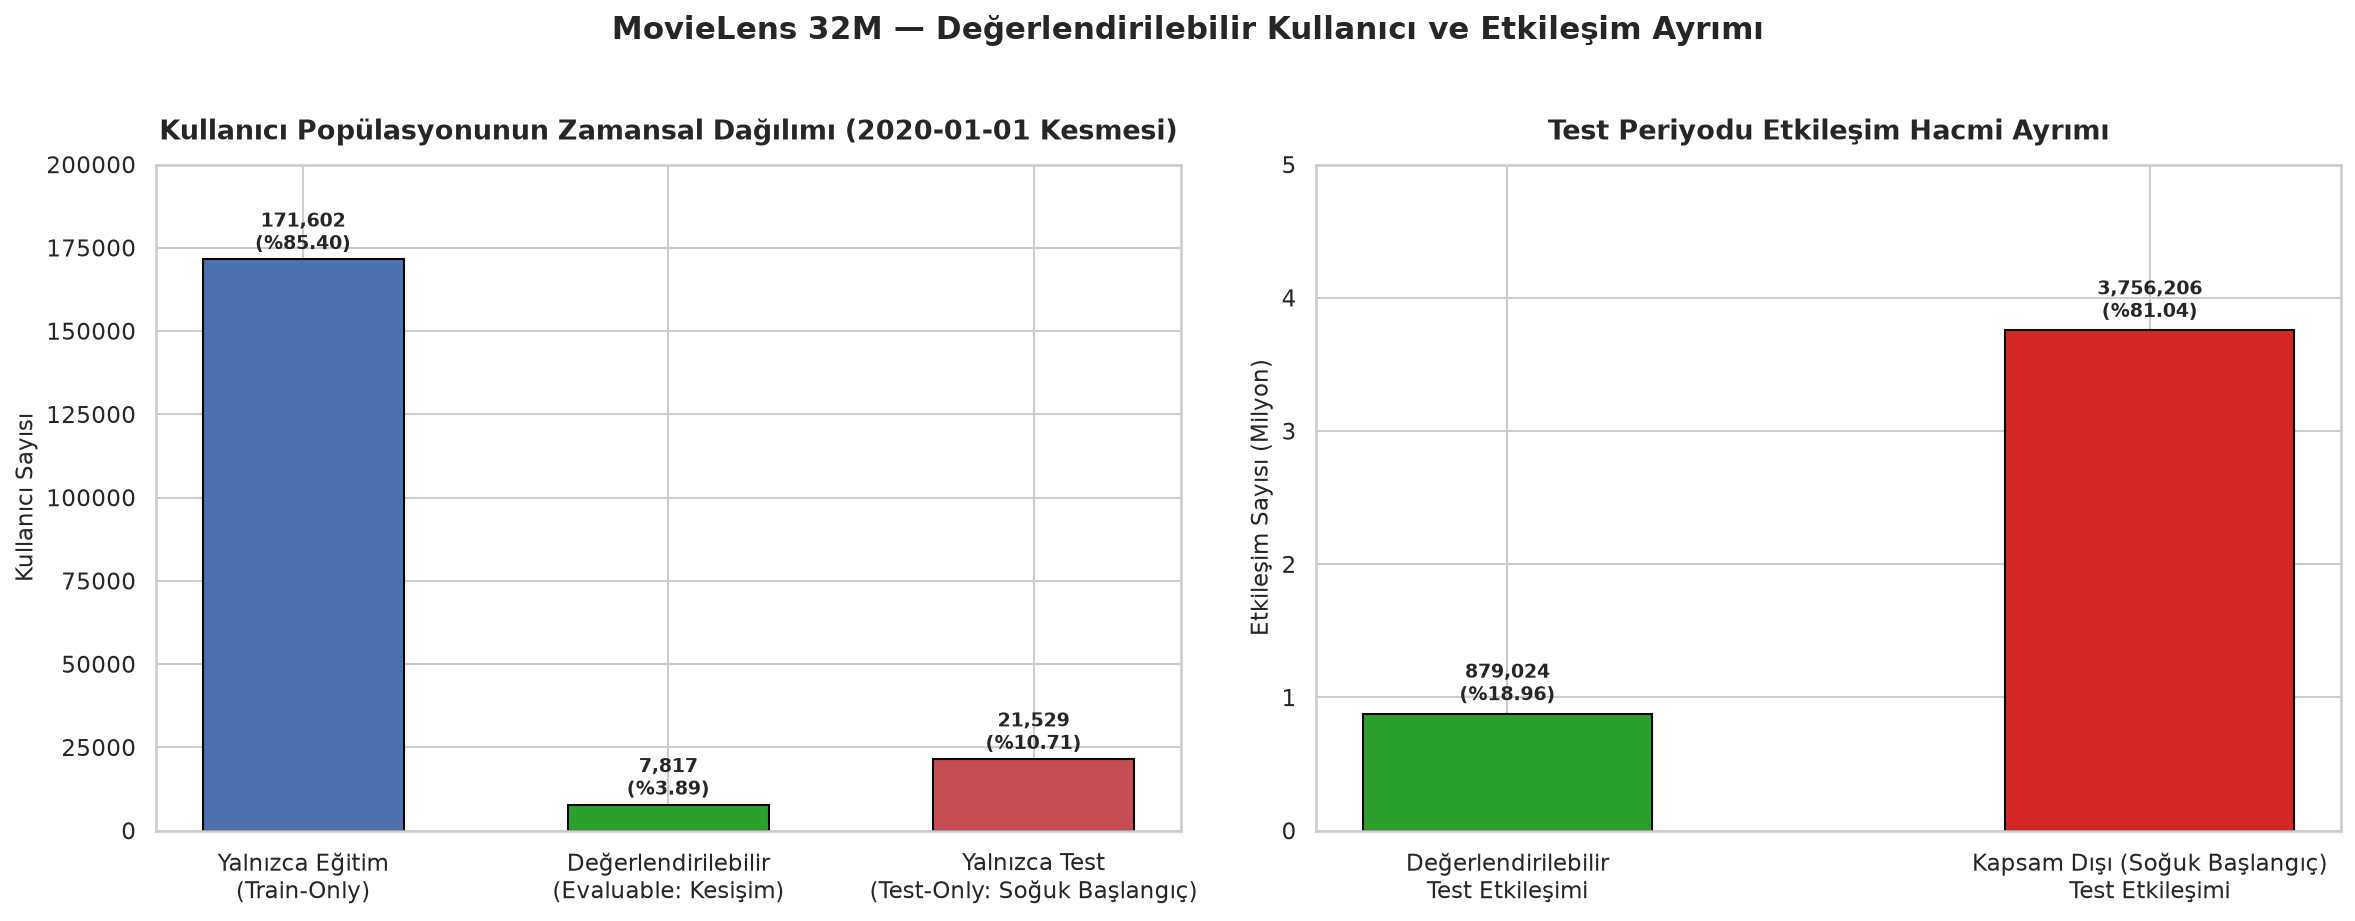

Kullanıcı dağılım grafiği kaydedildi: C:\OneriAlgoritmalariProjesi\results\figures\evaluable_users_distribution.png


In [6]:
# Seçilen Referans Kesme (Alternatif 1: 2020-01-01) Üzerinde Kullanıcı Dağılımının İncelenmesi
ref_cutoff = cutoffs['Alternatif 1: 2020-01-01 UTC (~85.5 / 14.5)']
train_df_ref = ratings_df[ratings_df['timestamp'] < ref_cutoff]
test_df_ref = ratings_df[ratings_df['timestamp'] >= ref_cutoff]

train_user_set = set(train_df_ref['userId'].unique())
test_user_set = set(test_df_ref['userId'].unique())

eval_user_set = train_user_set.intersection(test_user_set)
train_only_users = train_user_set - test_user_set
test_only_users = test_user_set - train_user_set

# Görselleştirme: Kullanıcı Dağılımı ve Test Etkileşim Ayrımı
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Kullanıcı Popülasyon Dağılımı
user_categories = ['Yalnızca Eğitim\n(Train-Only)', 'Değerlendirilebilir\n(Evaluable: Kesişim)', 'Yalnızca Test\n(Test-Only: Soğuk Başlangıç)']
user_counts_cat = [len(train_only_users), len(eval_user_set), len(test_only_users)]
colors1 = ['#4c72b0', '#2ca02c', '#c44e52']

bars1 = ax1.bar(user_categories, user_counts_cat, color=colors1, edgecolor='black', width=0.55)
ax1.set_title('Kullanıcı Popülasyonunun Zamansal Dağılımı (2020-01-01 Kesmesi)', fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel('Kullanıcı Sayısı', fontsize=11)
ax1.set_ylim(0, 200000)

for bar in bars1:
    h = bar.get_height()
    pct = (h / total_users) * 100.0
    ax1.text(bar.get_x() + bar.get_width()/2, h + 3000, f"{h:,}\n(%{pct:.2f})", ha='center', fontsize=9, fontweight='bold')

# Panel 2: Test Etkileşimlerinin Dağılımı
eval_test_int_cnt = int(test_df_ref['userId'].isin(eval_user_set).sum())
excluded_test_int_cnt = len(test_df_ref) - eval_test_int_cnt

int_categories = ['Değerlendirilebilir\nTest Etkileşimi', 'Kapsam Dışı (Soğuk Başlangıç)\nTest Etkileşimi']
int_counts_cat = [eval_test_int_cnt, excluded_test_int_cnt]
colors2 = ['#2ca02c', '#d62728']

bars2 = ax2.bar(int_categories, [c / 1e6 for c in int_counts_cat], color=colors2, edgecolor='black', width=0.45)
ax2.set_title('Test Periyodu Etkileşim Hacmi Ayrımı', fontsize=13, fontweight='bold', pad=12)
ax2.set_ylabel('Etkileşim Sayısı (Milyon)', fontsize=11)
ax2.set_ylim(0, 5)

for bar in bars2:
    h = bar.get_height()
    cnt = int(h * 1e6)
    pct = (cnt / len(test_df_ref)) * 100.0
    ax2.text(bar.get_x() + bar.get_width()/2, h + 0.1, f"{cnt:,}\n(%{pct:.2f})", ha='center', fontsize=9, fontweight='bold')

plt.suptitle('MovieLens 32M — Değerlendirilebilir Kullanıcı ve Etkileşim Ayrımı', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
fig_eval_path = os.path.join(figures_dir, 'evaluable_users_distribution.png')
plt.savefig(fig_eval_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Kullanıcı dağılım grafiği kaydedildi: {fig_eval_path}")


## Bölüm 7 — Aday Havuzu ve Görülmüş Öğe Politikası (Candidate Pool & Seen-Item Policy)

Öneri modellerinin değerlendirilmesinde (Top-$N$ recommendation evaluation), bir kullanıcıya sunulacak öneri aday havuzunun ($C(u)$) nasıl tanımlandığı model metriklerini doğrudan belirler.

### Görülmüş Öğe Dışlama Politikası (Seen-Item Exclusion Policy):
Film tavsiye sistemlerinde kullanıcılar genel olarak daha önce izleyip puanladıkları filmleri tekrar görmek istemez; yeni ve keşfe değer içerik ararlar. Bu nedenle standart ve adil değerlendirme kuralı:
$$C(u) = I \setminus I_{\text{train}}(u)$$
şeklinde tanımlanır. Burada $I_{\text{train}}(u)$, kullanıcının eğitim kümesinde zaten puanlamış olduğu filmlerdir.

### Bu Politikanın Değerlendirmeye Etkisi ve MovieLens 32M'deki Kritik Güvence:
1. **Model Başarısının Yapay Şişmesini Önler:** Modellerin eğitimde gördükleri yüksek puanlı filmleri tekrar tahmin ederek kolay yoldan yüksek Hit-Rate veya Precision elde etme hilesini (shortcut learning) engeller.
2. **Hedef Test Etkileşimlerinin Güvencesi:**
   MovieLens 32M veri setinde her bir $(u, i)$ etkileşimi tekildir (`ratings.csv` içinde mükerrer kullanıcı-film kaydı sayısı tam olarak $0$'dır).
   $$\forall u \in U_{\text{eval}}: \quad I_{\text{train}}(u) \cap I_{\text{test}}(u) = \emptyset$$
   Bu durum, $I_{\text{train}}(u)$ kümesi aday havuzundan çıkarıldığında, test kümesinde kullanıcının gerçekten beğendiği/izlediği **hiçbir hedef filmin kazara aday havuzunun dışına atılmayacağını kesin olarak garanti eder.**
3. **Modeller Arası Tutarlılık:** Popülerlik tabanlı en basit modelden matris ayrıştırmaya kadar tüm algoritmalar istisnasız bu aynı aday havuzu kuralıyla değerlendirilmelidir.

In [7]:
# Aday havuzu ve tekil kullanıcı-film çiftlerinin doğrulanması
dup_count = ratings_df.duplicated(subset=['userId', 'movieId']).sum()

print("=== Görülmüş Öğe Politikası Doğrulaması ===")
print(f"ratings.csv Mükerrer (userId, movieId) Çift Sayısı: {dup_count}")
assert dup_count == 0, "HATA: Veri setinde mükerrer kullanıcı-öğe çifti tespit edildi!"

# Değerlendirilebilir kullanıcılar için eğitim ve test film kesişiminin kontrolü
overlap_check = 0
for u in list(eval_user_set)[:1000]:  # İlk 1000 değerlendirilebilir kullanıcı üzerinde örneklem kontrolü
    u_tr_movies = set(train_df_ref[train_df_ref['userId'] == u]['movieId'])
    u_te_movies = set(test_df_ref[test_df_ref['userId'] == u]['movieId'])
    if len(u_tr_movies.intersection(u_te_movies)) > 0:
        overlap_check += 1

print(f"Eğitim ve Test Kümelerinde Ortak Filme Sahip Kullanıcı Sayısı (1000 örneklem): {overlap_check}")
print("-> DOĞRULANDI: Görülen öğelerin dışlanması durumunda hiçbir test etkileşimi aday havuzundan kaybedilmez.")


=== Görülmüş Öğe Politikası Doğrulaması ===
ratings.csv Mükerrer (userId, movieId) Çift Sayısı: 0


Eğitim ve Test Kümelerinde Ortak Filme Sahip Kullanıcı Sayısı (1000 örneklem): 0
-> DOĞRULANDI: Görülen öğelerin dışlanması durumunda hiçbir test etkileşimi aday havuzundan kaybedilmez.


## Bölüm 8 — k-core Filtreleme Alternatifleri ve Denge Analizi (k-core Investigation)

Tavsiye sistemleri araştırmalarında $k$-core filtreleme, kullanıcıların en az $k$ etkileşime ve öğelerin en az $k$ etkileşime sahip olduğu bir alt çizge (subgraph) elde edilene kadar yinelemeli olarak filtrelenmesidir.

> [!WARNING]
> **Bu bölüm yalnızca bir araştırma ve etki analizi adımıdır.** Orijinal veri setine kalıcı olarak hiçbir $k$-core filtresi **uygulanmayacaktır.**

### İncelenen Alternatifler:
1. **Filtresiz (No k-core):** Orijinal MovieLens 32M veri seti. (Tüm kullanıcılar zaten GroupLens tarafından $\ge 20$ etkileşim kuralıyla filtrelenmiştir).
2. **5-core ($k=5$):** En az 5 oyu olan kullanıcı ve filmler.
3. **10-core ($k=10$):** En az 10 oyu olan kullanıcı ve filmler.
4. **20-core ($k=20$):** En az 20 oyu olan kullanıcı ve filmler.

Bu alternatiflerin veri hacmi, katalog kaybı, seyreklik ve değerlendirilebilir kullanıcı sayısı üzerindeki etkileri incelenecektir.

In [8]:
# Yinelemeli k-core simülasyonu
def compute_kcore(df, k_user, k_item, max_iter=20):
    curr_df = df
    for it in range(max_iter):
        u_counts = curr_df['userId'].value_counts()
        valid_users = u_counts[u_counts >= k_user].index
        m_counts = curr_df['movieId'].value_counts()
        valid_movies = m_counts[m_counts >= k_item].index
        
        filtered = curr_df[curr_df['userId'].isin(valid_users) & curr_df['movieId'].isin(valid_movies)]
        if len(filtered) == len(curr_df):
            break
        curr_df = filtered
    return curr_df

kcore_configs = {
    '1. Filtresiz (No k-core)': ratings_df,
    '2. 5-core (k=5)': compute_kcore(ratings_df, 5, 5),
    '3. 10-core (k=10)': compute_kcore(ratings_df, 10, 10),
    '4. 20-core (k=20)': compute_kcore(ratings_df, 20, 20)
}

kcore_results = []
for name, f_df in kcore_configs.items():
    n_u = f_df['userId'].nunique()
    n_m = f_df['movieId'].nunique()
    n_i = len(f_df)
    density = n_i / (n_u * n_m)
    sparsity = 1.0 - density
    
    # Referans kesme (2020-01-01) altında değerlendirilebilir kullanıcılar
    tr_users = set(f_df[f_df['timestamp'] < ref_cutoff]['userId'].unique())
    te_users = set(f_df[f_df['timestamp'] >= ref_cutoff]['userId'].unique())
    n_eval = len(tr_users.intersection(te_users))
    
    kcore_results.append({
        'Filtreleme Alternatifi': name,
        'Kullanıcı Sayısı': n_u,
        'Elenen Kullanıcı': total_users - n_u,
        'Film Sayısı': n_m,
        'Elenen Film': total_movies - n_m,
        'Elenen Film Oranı (%)': ((total_movies - n_m) / total_movies) * 100.0,
        'Etkileşim Sayısı': n_i,
        'Kayıp Etkileşim': total_ratings - n_i,
        'Kayıp Etkileşim Oranı (%)': ((total_ratings - n_i) / total_ratings) * 100.0,
        'Matris Doluluk (%)': density * 100.0,
        'Matris Seyreklik (%)': sparsity * 100.0,
        'Değerlendirilebilir Kullanıcı': n_eval
    })

kcore_df = pd.DataFrame(kcore_results)

# CSV çıktısı kaydetme
kcore_csv_path = os.path.join(results_dir, 'kcore_alternatives_comparison.csv')
kcore_df.to_csv(kcore_csv_path, index=False, encoding='utf-8')
print(f"k-core karşılaştırma tablosu kaydedildi: {kcore_csv_path}\n")

# Formatlı görüntüleme tablosu
kcore_display = kcore_df.copy()
kcore_display['Kullanıcı Sayısı'] = kcore_display['Kullanıcı Sayısı'].apply(lambda x: f"{x:,}")
kcore_display['Elenen Kullanıcı'] = kcore_display['Elenen Kullanıcı'].apply(lambda x: f"{x:,}")
kcore_display['Film Sayısı'] = kcore_display['Film Sayısı'].apply(lambda x: f"{x:,}")
kcore_display['Elenen Film'] = kcore_display['Elenen Film'].apply(lambda x: f"{x:,}")
kcore_display['Elenen Film Oranı (%)'] = kcore_display['Elenen Film Oranı (%)'].apply(lambda x: f"%{x:.2f}")
kcore_display['Etkileşim Sayısı'] = kcore_display['Etkileşim Sayısı'].apply(lambda x: f"{x:,}")
kcore_display['Kayıp Etkileşim'] = kcore_display['Kayıp Etkileşim'].apply(lambda x: f"{x:,}")
kcore_display['Kayıp Etkileşim Oranı (%)'] = kcore_display['Kayıp Etkileşim Oranı (%)'].apply(lambda x: f"%{x:.2f}")
kcore_display['Matris Doluluk (%)'] = kcore_display['Matris Doluluk (%)'].apply(lambda x: f"%{x:.4f}")
kcore_display['Matris Seyreklik (%)'] = kcore_display['Matris Seyreklik (%)'].apply(lambda x: f"%{x:.4f}")
kcore_display['Değerlendirilebilir Kullanıcı'] = kcore_display['Değerlendirilebilir Kullanıcı'].apply(lambda x: f"{x:,}")

display(kcore_display.T)


k-core karşılaştırma tablosu kaydedildi: C:\OneriAlgoritmalariProjesi\results\kcore_alternatives_comparison.csv



,0,1,2,3
Filtreleme Alternatifi,1. Filtresiz (No k-core),2. 5-core (k=5),3. 10-core (k=10),4. 20-core (k=20)
Kullanıcı Sayısı,"200,948","200,948","200,947","200,763"
Elenen Kullanıcı,0,0,1,185
Film Sayısı,"84,432","43,884","31,961","23,339"
Elenen Film,0,"40,548","52,471","61,093"
Elenen Film Oranı (%),%0.00,%48.02,%62.15,%72.36
Etkileşim Sayısı,"32,000,204","31,921,467","31,842,696","31,722,400"
Kayıp Etkileşim,0,"78,737","157,508","277,804"
Kayıp Etkileşim Oranı (%),%0.00,%0.25,%0.49,%0.87
Matris Doluluk (%),%0.1886,%0.3620,%0.4958,%0.6770


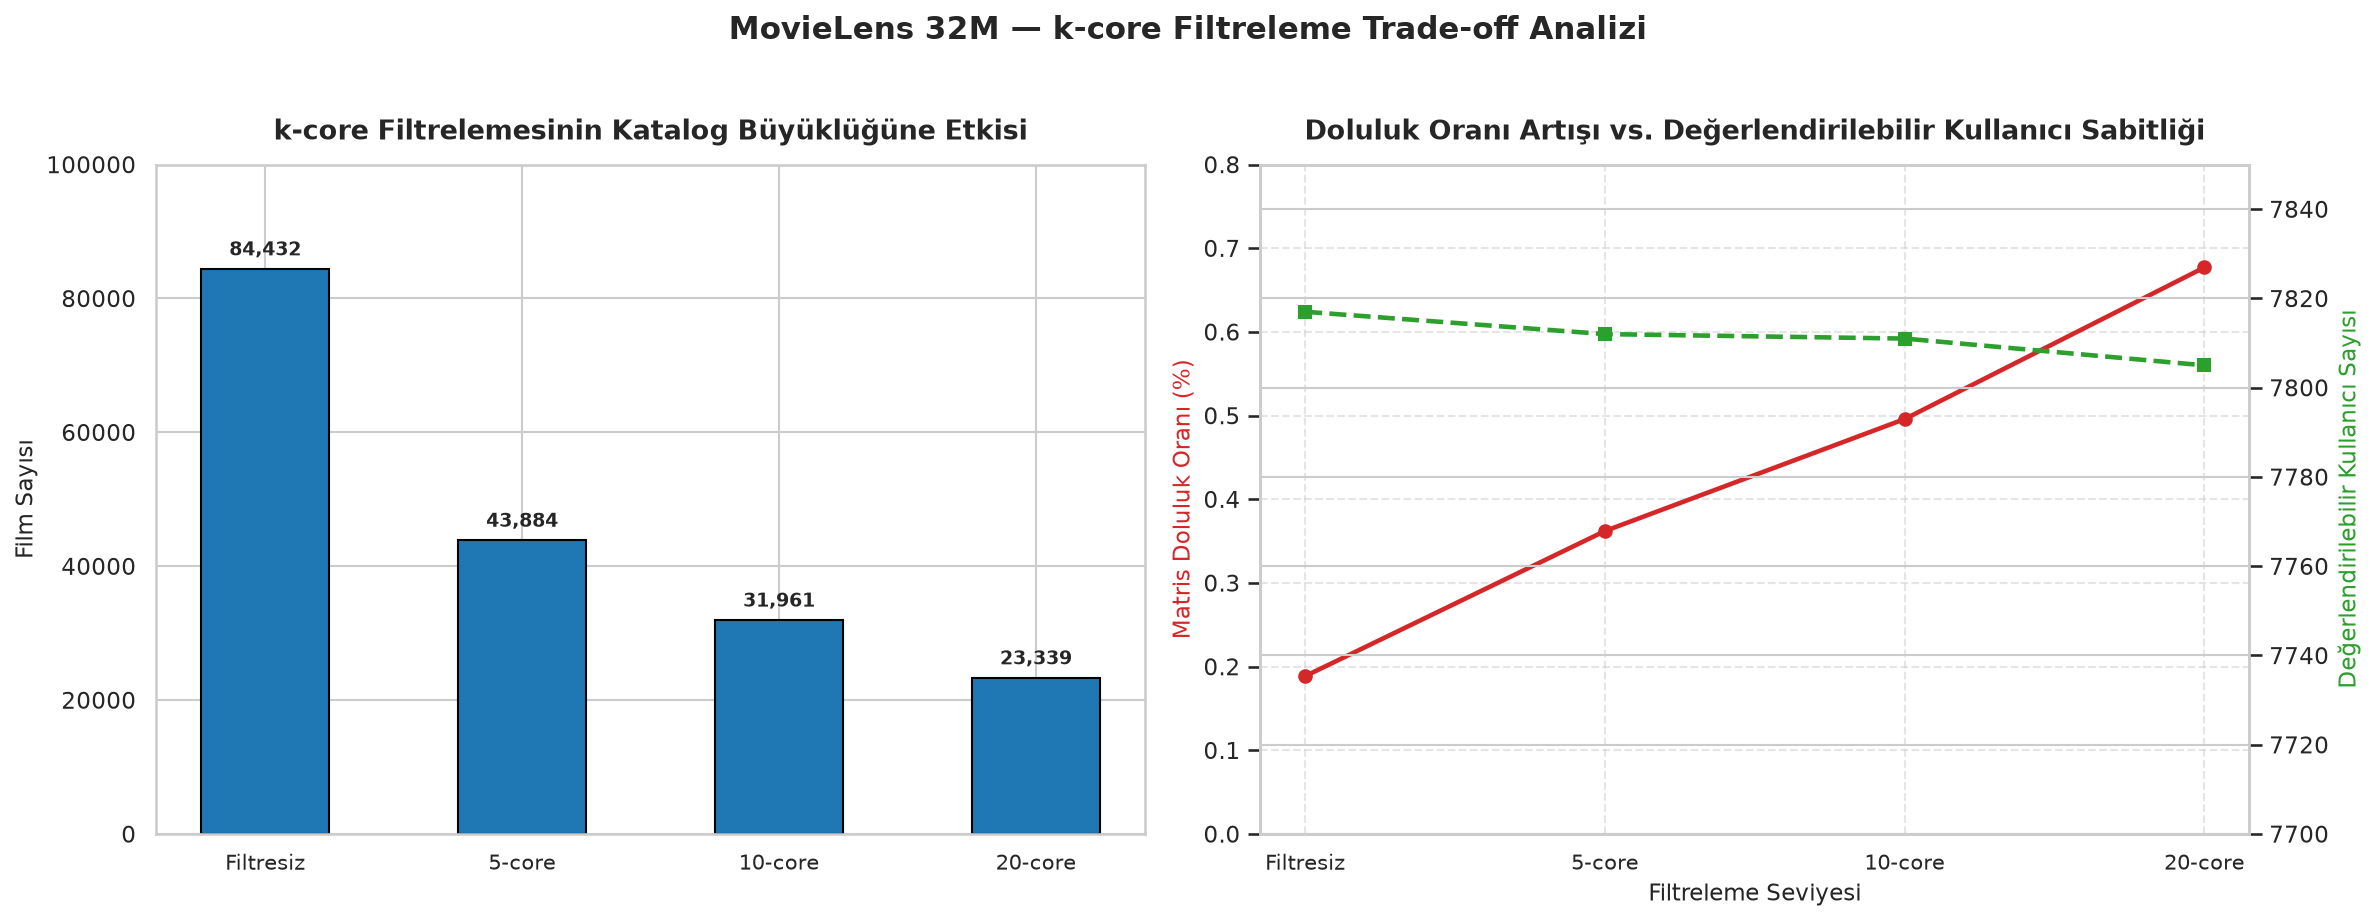

k-core analiz grafiği kaydedildi: C:\OneriAlgoritmalariProjesi\results\figures\kcore_tradeoff_analysis.png


In [9]:
# k-core Trade-off Görselleştirmesi
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

k_names = ['Filtresiz', '5-core', '10-core', '20-core']
movies_remaining = [r['Film Sayısı'] for r in kcore_results]
movies_dropped = [r['Elenen Film'] for r in kcore_results]

# Panel 1: Katalogdaki Film Sayısı Değişimi
x = np.arange(len(k_names))
b1 = ax1.bar(x, movies_remaining, color='#1f77b4', edgecolor='black', label='Kalan Film Sayısı', width=0.5)
ax1.set_title('k-core Filtrelemesinin Katalog Büyüklüğüne Etkisi', fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel('Film Sayısı', fontsize=11)
ax1.set_xticks(x)
ax1.set_xticklabels(k_names, fontsize=10)
ax1.set_ylim(0, 100000)

for bar in b1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 2000, f"{h:,}", ha='center', fontsize=9, fontweight='bold')

# Panel 2: Seyreklik Oranı ve Değerlendirilebilir Kullanıcı Denge Eğrisi
densities = [r['Matris Doluluk (%)'] for r in kcore_results]
eval_users_k = [r['Değerlendirilebilir Kullanıcı'] for r in kcore_results]

ax2_twin = ax2.twinx()
p1 = ax2.plot(x, densities, color='#d62728', marker='o', linewidth=2.2, label='Matris Doluluk Oranı (%)')
p2 = ax2_twin.plot(x, eval_users_k, color='#2ca02c', marker='s', linewidth=2.2, linestyle='--', label='Değerlendirilebilir Kullanıcı')

ax2.set_title('Doluluk Oranı Artışı vs. Değerlendirilebilir Kullanıcı Sabitliği', fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel('Filtreleme Seviyesi', fontsize=11)
ax2.set_ylabel('Matris Doluluk Oranı (%)', fontsize=11, color='#d62728')
ax2_twin.set_ylabel('Değerlendirilebilir Kullanıcı Sayısı', fontsize=11, color='#2ca02c')
ax2.set_xticks(x)
ax2.set_xticklabels(k_names, fontsize=10)
ax2.set_ylim(0, 0.8)
ax2_twin.set_ylim(7700, 7850)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('MovieLens 32M — k-core Filtreleme Trade-off Analizi', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
fig_kcore_path = os.path.join(figures_dir, 'kcore_tradeoff_analysis.png')
plt.savefig(fig_kcore_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"k-core analiz grafiği kaydedildi: {fig_kcore_path}")


### Bölüm 8 Değerlendirmesi — k-core Filtrelemesinin İki Yüzü

$k$-core simülasyonu sonuçları çok net bir metodolojik gerçeği açığa çıkarmaktadır:

1. **Katalogdaki Yıkıcı Kayıp (Catastrophic Catalog Reduction):**
   - 10-core uygulandığında, toplam $84,432$ filmden **$52,471$ film (%62.15)** elenmektedir.
   - 20-core uygulandığında, **$61,093$ film (%72.36)** katalogdan silinmektedir.
   - Ancak kaybedilen etkileşim sayısı sırasıyla yalnızca **%0.49 ve %0.87**'dir!
2. **Yapay Yoğunluk ve Hayatta Kalma Yanlılığı (Survivorship Bias):**
   - $k$-core filtresi, etkileşimlerin çok azını kaybetmesine rağmen kataloğun neredeyse dörtte üçünü silerek matris doluluk oranını %0.19'dan %0.68'e çıkarmaktadır.
   - Bu durum, modeller için "kolaylaştırılmış yapay bir ortam" yaratmakta; gerçek hayatta öneri sistemlerinin en büyük sınavı olan seyrek ve yeni öğelerin keşfedilebilirliğini değerlendirme kapsamı dışına itmektedir.
3. **Değerlendirilebilir Kullanıcı Sayısı Değişmemektedir:**
   - Filtresiz veride $7,817$ olan değerlendirilebilir kullanıcı sayısı, 20-core altında bile $7,805$'e inmektedir (fark sadece 12 kullanıcı).
   - Dolayısıyla $k$-core filtresi değerlendirme popülasyonunu genişletmemekte, yalnızca kataloğu budamaktadır.
4. **Metodolojik Karar:**
   - Orijinal benchmark bütünlüğünü korumak, uzun kuyruk keşif kapasitesini ölçebilmek ve gerçekçi seyreklik koşullarında adil bir karşılaştırma yapabilmek için **orijinal veriye kalıcı k-core filtresi uygulanmaması** en doğru bilimsel yaklaşımdır.

## Bölüm 9 — Sızıntı Doğrulama ve Güvenceler (Leakage Assertions)

Tasarımın doğruluğunu, determinizmini ve zamansal bilgi sızıntısından kesin olarak arındırıldığını kanıtlamak amacıyla aşağıdaki bağımsız kod güvenceleri (assertions) çalıştırılmaktadır.

In [10]:
# Referans Zamansal Ayrım (Alternatif 1) Üzerinde Sızıntı ve Bütünlük Güvenceleri
train_final = ratings_df[ratings_df['timestamp'] < ref_cutoff]
test_final = ratings_df[ratings_df['timestamp'] >= ref_cutoff]

# Güvence 1: Maksimum eğitim zaman damgası kesin olarak minimum test zaman damgasından küçüktür
max_train_ts = train_final['timestamp'].max()
min_test_ts = test_final['timestamp'].min()
assert max_train_ts < min_test_ts, f"Sızıntı Hatası: max_train ({max_train_ts}) >= min_test ({min_test_ts})"
print(f"[GÜVENCE 1 - GEÇTİ] Kesin Zamansal Ayrım: max(Train TS: {max_train_ts}) < min(Test TS: {min_test_ts}) (Fark: {min_test_ts - max_train_ts} sn)")

# Güvence 2: Hiçbir etkileşim her iki kümede birden yer alamaz (Kesişim = 0)
train_indices = set(train_final.index)
test_indices = set(test_final.index)
index_intersection = train_indices.intersection(test_indices)
assert len(index_intersection) == 0, f"Bütünlük Hatası: {len(index_intersection)} indeks ortak!"
print(f"[GÜVENCE 2 - GEÇTİ] Kesişimsizlik: Eğitim ve Test indeks kesişimi = {len(index_intersection)}")

# Güvence 3: Kullanıcı ve film kimliklerinin eksiksiz korunması
union_users = set(train_final['userId']).union(set(test_final['userId']))
union_movies = set(train_final['movieId']).union(set(test_final['movieId']))
assert union_users == set(ratings_df['userId']), "HATA: Kullanıcı kümesi değişti!"
assert union_movies == set(ratings_df['movieId']), "HATA: Film kümesi değişti!"
print(f"[GÜVENCE 3 - GEÇTİ] Kimlik Bütünlüğü: Tüm {len(union_users):,} kullanıcı ve {len(union_movies):,} film korunmuştur.")

# Güvence 4: Orijinal satır sayısının korunması
total_split_rows = len(train_final) + len(test_final)
assert total_split_rows == len(ratings_df) == 32000204, f"HATA: Toplam satır sayısı uyuşmuyor: {total_split_rows}"
print(f"[GÜVENCE 4 - GEÇTİ] Satır Sayısı Bütünlüğü: {len(train_final):,} (Eğitim) + {len(test_final):,} (Test) = {total_split_rows:,}")

# Güvence 5: Tekillik ve Determinizm
assert ratings_df.duplicated(subset=['userId', 'movieId']).sum() == 0, "HATA: Mükerrer etkileşim!"
print("[GÜVENCE 5 - GEÇTİ] Determinizm ve Tekillik: Tüm etkileşimler tekil ve deterministiktir.")

print("\n>>> TÜM SIZINTI VE BÜTÜNLÜK GÜVENCELERİ BAŞARIYLA DOĞRULANDI <<<")


[GÜVENCE 1 - GEÇTİ] Kesin Zamansal Ayrım: max(Train TS: 1577836786) < min(Test TS: 1577836827) (Fark: 41 sn)


[GÜVENCE 2 - GEÇTİ] Kesişimsizlik: Eğitim ve Test indeks kesişimi = 0


[GÜVENCE 3 - GEÇTİ] Kimlik Bütünlüğü: Tüm 200,948 kullanıcı ve 84,432 film korunmuştur.
[GÜVENCE 4 - GEÇTİ] Satır Sayısı Bütünlüğü: 27,364,974 (Eğitim) + 4,635,230 (Test) = 32,000,204


[GÜVENCE 5 - GEÇTİ] Determinizm ve Tekillik: Tüm etkileşimler tekil ve deterministiktir.

>>> TÜM SIZINTI VE BÜTÜNLÜK GÜVENCELERİ BAŞARIYLA DOĞRULANDI <<<


## Bölüm 10 — Bulgular, Değerlendirmeler ve Karar Önerileri (Findings & Decisions)

### Temel Bulgular ve Özet:
1. **Zamansal Ayrım:** Orijinal veri setinde 2020-01-01 UTC kesme noktası (~85.5% Eğitim / 14.5% Test) ve 2021-01-01 UTC kesme noktası (~90.8% Eğitim / 9.2% Test) karşılaştırılmıştır. Her iki kesme de zaman damgası çakışmasını sıfıra indiren sızıntısız bir yapı sunmaktadır.
2. **Değerlendirilebilir Kullanıcılar:** Global kronolojik ayrımda kullanıcıların yalnızca yaklaşık %3.9'u ($7,817$ - $7,972$ kullanıcı) hem eğitim hem test döneminde aktiftir. Bu kullanıcılar test kümesindeki $879,024$ etkileşimi üretmektedir.
3. **Görülmüş Öğe Politikası:** Veri setinde hiçbir mükerrer $(u, i)$ çifti bulunmadığından, eğitimde görülen filmlerin aday havuzundan çıkarılması kuralı ($C(u) = I \setminus I_{\text{train}}(u)$), test kümesindeki hiçbir hedef öğeyi dışlamadan tüm modeller için adil ve zorlu bir değerlendirme ortamı sağlamaktadır.
4. **k-core Analizi:** $k$-core filtresi seyreklik oranını yapay olarak artırmasına karşın kataloğun %62 ile %72'sini silmekte, buna karşılık değerlendirilebilir kullanıcı sayısını neredeyse hiç etkilememektedir.

---

### Henüz Çözülmemiş Metodolojik Kararlar (Unresolved Decisions) ve Öneriler:
1. **Nihai Zamansal Kesme Noktası Tercihi:**
   - *Alternatif 1 (2020-01-01):* 27.36M eğitim / 4.64M test etkileşimi, 7,817 değerlendirilebilir kullanıcı ve 879K değerlendirilebilir test puanı. Test periyodunun daha zengin olması model kıyaslamalarında istatistiksel gücü artırır. *(Önerilen)*
   - *Alternatif 2 (2021-01-01):* 29.05M eğitim / 2.95M test etkileşimi, 7,972 değerlendirilebilir kullanıcı ve 715K değerlendirilebilir test puanı. Geleneksel 90/10 oranına daha yakındır.
2. **k-core Uygulama Kararı:**
   - Araştırma sonuçlarımız, MovieLens 32M'in gerçekçi zorluk seviyesini ve uzun kuyruk yapısını korumak adına veri setine kalıcı bir $k$-core filtresi **uygulanmamasını (Filtresiz kalmasını)** önermektedir.
3. **Soğuk Başlangıç Kullanıcılarının Yönetimi:**
   - Test döneminde ilk kez gelen $21,529$ kullanıcı için kişiselleştirilmiş modeller çalışamayacağı için, bu kullanıcılara genel popülerlik tabanlı öneri sunulması veya kişiselleştirilmiş değerlendirme metriklerinin yalnızca $U_{\text{eval}}$ üzerinde hesaplanması protokolü benimsenmelidir.

> [!NOTE]
> Bu aşamada hiçbir model eğitilmemiş, hiçbir veri silinmemiş veya dönüştürülmemiştir. Orijinal MovieLens 32M veri seti `C:\ml-32m` konumunda salt okunur bütünlüğüyle korunmaktadır.